In [22]:
import pandas as pd
import requests
from PIL import Image
import io
import ipywidgets as widgets
from IPython.display import display, clear_output

In [23]:
pokemon_df = pd.read_csv('data/pokemon_data.csv')
p_images_df = pd.read_csv('data/pokemon_801.csv')

In [24]:
merged_df = pd.merge(pokemon_df, p_images_df, on='name')

In [25]:
print(merged_df.iloc[0]["name"])
print(merged_df.iloc[0].image_url)

Bulbasaur
https://raw.githubusercontent.com/PokeAPI/sprites/master/sprites/pokemon/other/official-artwork/1.png


In [26]:
m_url = merged_df.loc[merged_df.name == "Meowth", "image_url"].item()
m_url

m_response = requests.get

In [27]:
my_pokemon = merged_df.sample().iloc[0]
opp_pokemon = merged_df.sample().iloc[0]

#Let's showcase them
pokemon_url = my_pokemon.image_url
response = requests.get(pokemon_url)
pokemon_img = Image.open(io.BytesIO(response.content))

# save names
my_name = my_pokemon['name']
opp_name = opp_pokemon['name']

opp_url = opp_pokemon.image_url
response = requests.get(opp_url)
opp_img = Image.open(io.BytesIO(response.content))



if my_pokemon.hp > opp_pokemon.hp:
    print(f"{my_name} won!")
elif my_pokemon.hp < opp_pokemon.hp:
    print(f"{opp_name} won!")
else:
    print("it's a tie!")

Gurdurr won!


In [28]:
# function for displaying image
def get_image_from_url(url):
    response = requests.get(url)
    img = Image.open(io.BytesIO(response.content))
    display(img)

In [41]:
def battle():
    text_input = widgets.Text(
        placeholder = 'Who do you choose?',
        description = 'Choose your Pokemon!',
        layout = widgets.Layout(width='300px')
    )
    button = widgets.Button(
        description='Ready for battle!',
        button_style='danger'
    )
    output = widgets.Output()

    def on_battle_click(b):
        with output:
            clear_output()

            pokemon_name = text_input.value.strip().capitalize()

            match = merged_df[merged_df['name'].str.capitalize() == pokemon_name]

            if match.empty:
                print(f"'{pokemon_name}' not found!"

            return

    my_pokemon = merged_df.sample().iloc[0]
    opp_pokemon = merged_df.sample().iloc[0]
    
    #Let's showcase them
    # pokemon_url = my_pokemon.image_url
    # response = requests.get(pokemon_url)
    # pokemon_img = Image.open(io.BytesIO(response.content))
    
    # save names
    my_name = my_pokemon['name']
    opp_name = opp_pokemon['name']
    
    # opp_url = opp_pokemon.image_url
    # response = requests.get(opp_url)
    # opp_img = Image.open(io.BytesIO(response.content))
    
    
    print(f"I choose you...{my_name}! HP = {my_pokemon.hp}")
    get_image_from_url(my_pokemon.image_url)
    print(f"It's.....{opp_name} HP = {opp_pokemon.hp}")
    get_image_from_url(my_pokemon.image_url)
    
    
    if my_pokemon.hp > opp_pokemon.hp:
        print(f"{my_name} won!")
    elif my_pokemon.hp < opp_pokemon.hp:
        print(f"{opp_name} won!")
    else:
        print("it's a tie!")

    button.on_click(on_battle_click)
    display(widgets.VBox([text_input,button,output]))

SyntaxError: '(' was never closed (2290632427.py, line 22)

I choose you...Banette! HP = 64


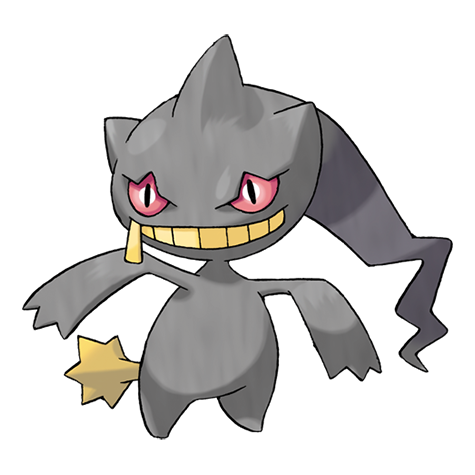

It's.....Taillow HP = 40


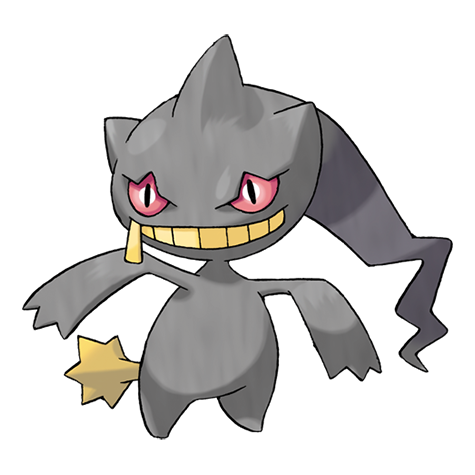

Banette won!


In [42]:
battle()